# Cuadernillo 5 · Interpretación y conclusión

**Autor:** Dilan Aldana - Jeison Del Rio

**Objetivo.** Entender qué variables pesan en la decisión, explicar una decisión concreta, guardar el modelo y cerrar el proyecto.

**Fecha:** 22 de noviembre de 2026

**Desarrollo.** Interpretación global (coeficientes), interpretación individual (una solicitud), guardado del modelo y **conclusión** con lo aprendido, las limitaciones y los siguientes pasos.

In [1]:
# Python básico
import sys
import warnings
from pathlib import Path

# Datos y gráficos
import joblib
import matplotlib.pyplot as plt
import pandas as pd

# Modelos
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(RAIZ))

from src import analisis
from src.analisis import AZUL, ROJO

warnings.filterwarnings("ignore")
analisis.configurar_estilo()

print("Todo listo")


Todo listo



**Qué hace esta celda.** Prepara `joblib` para guardar el modelo, los gráficos y las funciones del proyecto.

## Preparación

El cuaderno se puede ejecutar solo: repite los pasos de los cuadernillos 1 a 4 y entrena el modelo final con `C = 0,01`.

In [2]:
# Preparación: se repiten los pasos de los cuadernillos 1 a 3
# para que este cuaderno funcione solo.
df = pd.read_csv(RAIZ / "data" / "solicitudes_prestamos.csv")
df["Aprobado"] = (df["Loan_Status"] == "Y").astype(int)

df = df.drop(columns="Loan_ID")
df["Dependents"] = df["Dependents"].replace("3+", "3").astype(float)
for columna in ["Gender", "Married", "Self_Employed"]:
    df[columna] = df[columna].fillna("Sin dato")

df["Ingreso_Total"] = df["ApplicantIncome"] + df["CoapplicantIncome"]
df = df.drop(columns=["ApplicantIncome", "CoapplicantIncome"])

y = df.pop("Aprobado")
X = pd.get_dummies(df.drop(columns="Loan_Status"), drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Entrenamiento: {X_train.shape[0]} solicitudes")
print(f"Prueba:        {X_test.shape[0]} solicitudes")
print(f"Variables:     {X.shape[1]}")


def crear_logistica(C=1):
    """Pipeline de regresión logística; C controla la regularización."""
    return Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
        ("modelo", LogisticRegression(
            C=C, max_iter=2000, class_weight="balanced", random_state=42
        )),
    ])


# C = 0,01 fue el valor elegido en el cuadernillo 4.
modelo_final = crear_logistica(C=0.01).fit(X_train, y_train)

print("Modelo final: regresión logística con C = 0,01")


Entrenamiento: 491 solicitudes
Prueba:        123 solicitudes
Variables:     14
Modelo final: regresión logística con C = 0,01



Los datos quedan separados (491 / 123) y el modelo final entrenado. No hace falta repetir la búsqueda de `C`: ya se sabe que el mejor valor es 0,01 (cuadernillo 4).

## 1. ¿Qué variables pesan más?

La regresión logística asigna un **coeficiente** a cada variable: positivo empuja a aprobar, negativo a rechazar. Como todas están en la misma escala (cuadernillo 4), los puntajes se comparan entre sí.

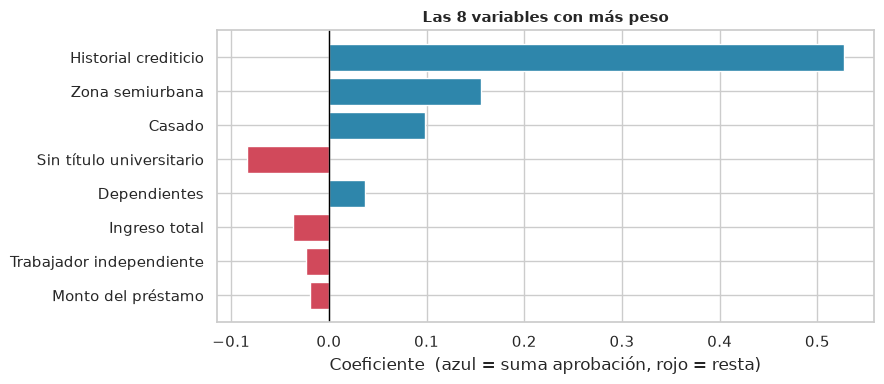

,variable,coeficiente
0,Historial crediticio,0.527
1,Zona semiurbana,0.155
2,Casado,0.098
3,Sin título universitario,-0.084
4,Dependientes,0.037
5,Ingreso total,-0.037
6,Trabajador independiente,-0.024
7,Monto del préstamo,-0.020


In [3]:
coeficientes = pd.Series(
    modelo_final.named_steps["modelo"].coef_[0],
    index=X.columns,
)

# Quitamos las categorías "Sin dato" para que el gráfico hable de variables reales
coeficientes = coeficientes[~coeficientes.index.str.contains("Sin dato")]
coeficientes = coeficientes.sort_values(key=abs, ascending=False).head(8)

nombres = {
    "Credit_History": "Historial crediticio",
    "Property_Area_Semiurban": "Zona semiurbana",
    "Property_Area_Urban": "Zona urbana",
    "Married_Yes": "Casado",
    "Married_Sin dato": "Estado civil sin dato",
    "Education_Not Graduate": "Sin título universitario",
    "Ingreso_Total": "Ingreso total",
    "Dependents": "Dependientes",
    "Self_Employed_Yes": "Trabajador independiente",
    "LoanAmount": "Monto del préstamo",
    "Loan_Amount_Term": "Plazo",
    "Gender_Male": "Hombre",
    "Gender_Sin dato": "Género sin dato",
    "Self_Employed_Sin dato": "Empleo sin dato",
}

etiquetas = [nombres.get(col, col) for col in coeficientes.index]
valores = coeficientes.values
colores = [AZUL if valor > 0 else ROJO for valor in valores]

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(etiquetas[::-1], valores[::-1], color=colores[::-1])
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Coeficiente  (azul = suma aprobación, rojo = resta)")
ax.set_title("Las 8 variables con más peso")
plt.tight_layout()
plt.show()

pd.DataFrame({"variable": etiquetas, "coeficiente": valores.round(3)})

- **Historial crediticio (0,53):** con diferencia, la que más empuja a aprobar.
- **Zona semiurbana (0,16)** y **casado (0,10):** suman un poco.
- **Sin título universitario (−0,08):** resta un poco.
- **Ingreso total (−0,04)** y **monto (−0,02):** casi no mueven la decisión cuando ya se conoce el historial.

Azul acerca a la aprobación, rojo aleja; el largo de la barra indica cuánto pesa.

Estos pesos describen **estos 614 datos**, no la vida real: el modelo no dice que casarse aumente la probabilidad de que aprueben un préstamo.

**¿Y SHAP?** SHAP reparte la "culpa" de una decisión entre las variables. En un modelo lineal no hace falta una librería: la predicción se descompone exactamente como **valor base + suma de contribuciones**. Cada variable suma o resta según su coeficiente y su valor en esa solicitud.

## 2. Explicación de una solicitud concreta

Se toma una solicitud rechazada del conjunto de prueba y se descompone su predicción.

In [4]:
caso = X_test[y_test == 0].iloc[[0]]
tabla_caso, base, log_odds, probabilidad = analisis.explicar_caso(modelo_final, caso)

print(f"Valor base del modelo (log-odds): {base:.2f}")
print(f"Suma de las contribuciones:       {log_odds - base:.2f}")
print(f"Predicción final (log-odds):      {log_odds:.2f}")
print(f"Probabilidad de aprobación:       {probabilidad:.2f}")
print(f"Decisión del modelo: {'APROBAR' if probabilidad >= 0.5 else 'RECHAZAR'}")
print("Resultado real: RECHAZAR")

tabla_caso["variable"] = tabla_caso["variable"].map(lambda v: nombres.get(v, v))
tabla_caso.round(3)


Valor base del modelo (log-odds): 0.10
Suma de las contribuciones:       -1.54
Predicción final (log-odds):      -1.44
Probabilidad de aprobación:       0.19
Decisión del modelo: RECHAZAR
Resultado real: RECHAZAR



,variable,valor,contribucion
3,Historial crediticio,0.0,-1.327
8,Casado,0.0,-0.134
12,Zona semiurbana,0.0,-0.120
9,Sin título universitario,0.0,0.045
0,Dependientes,0.0,-0.028
11,Trabajador independiente,0.0,0.009
13,Zona urbana,0.0,0.009
5,Hombre,1.0,-0.008


El modelo parte de un valor base de **0,10** (en escala *log-odds*) y las variables restan **1,54**: el resultado es **−1,44**, una probabilidad de aprobación de **0,19**. Como es menor que 0,5, **rechaza**, y acierta: el resultado real también era rechazar.

El **historial crediticio** resta **1,33**, mucho más que todas las demás juntas: esta persona no tenía historial y eso inclinó la balanza.

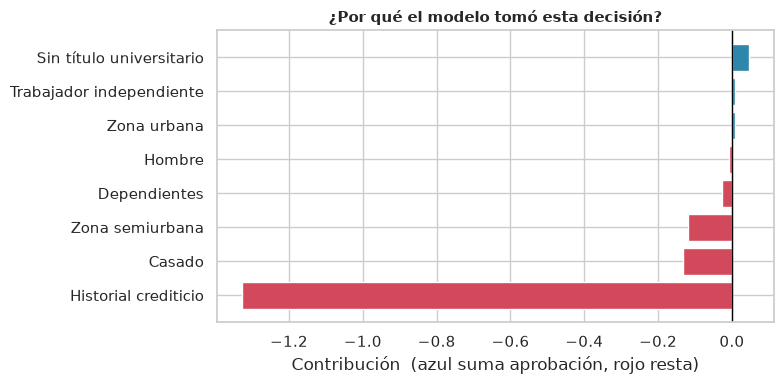

In [5]:
tabla_plot = tabla_caso.sort_values("contribucion")
colores = [AZUL if valor > 0 else ROJO for valor in tabla_plot["contribucion"]]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(tabla_plot["variable"], tabla_plot["contribucion"], color=colores)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Contribución  (azul suma aprobación, rojo resta)")
ax.set_title("¿Por qué el modelo tomó esta decisión?")
plt.tight_layout()
plt.show()

Cada barra es lo que una variable suma (azul) o resta (rojo). El historial es la barra roja más larga, la razón principal del rechazo; las demás casi no cambian el resultado.

El gráfico de coeficientes explica el modelo en general; este explica una sola decisión, la pregunta "¿por qué a mí?".

## 3. Guardar el modelo

El modelo son tres pasos encadenados: imputar, escalar y calcular la probabilidad. Se guarda completo para no repetir el proceso.

In [6]:
ruta = RAIZ / "models" / "modelo_entrenado.joblib"
ruta.parent.mkdir(exist_ok=True)
joblib.dump(modelo_final, ruta)
print("Modelo guardado en:", ruta)

# Comprobar que se puede cargar
modelo_cargado = joblib.load(ruta)
print("Probabilidades de ejemplo:", modelo_cargado.predict_proba(X_test.head(3))[:, 1].round(2))


Modelo guardado en: /home/dilan/Work/proyecto_prestamos/models/modelo_entrenado.joblib
Probabilidades de ejemplo: [0.19 0.66 0.55]



Se guardó en `models/modelo_entrenado.joblib` y se volvió a cargar bien: las probabilidades de ejemplo son 0,19, 0,66 y 0,55.

El archivo incluye la imputación y el escalado, así que para predecir una solicitud nueva basta con cargarlo y pasarle los datos.

## 4. Conclusión

**Qué se hizo.** Se analizaron 614 solicitudes, se limpiaron y transformaron, se compararon tres modelos y se ajustó `C` con validación cruzada, enfocando el ajuste en los falsos negativos.

**Resultado.** La logística con `C = 0,01` y `class_weight="balanced"` es el modelo final: AUC 0,844, exactitud 84,6 %, recall 94,1 % y F1 0,894. Acierta 104 de 123 casos y deja fuera solo 5 aprobados reales (antes 10). El Random Forest se descartó por memorizar (AUC 1,00 en entrenamiento, 0,83 en prueba).

**Lectura de negocio.** El **historial crediticio** es la variable que más pesa (79,6 % de aprobación con historial, 7,9 % sin historial). La zona y el estado civil ajustan; el ingreso y el monto casi no cambian la decisión cuando ya se conoce el historial.

**Cómo usarlo.** Para **priorizar la revisión**, no para rechazar automáticamente: lo que el modelo aprueba pasa a verificación documental. Con ese proceso, un FP cuesta una revisión y un FN cuesta un cliente; por eso se aceptó el ajuste que reduce los FN a cambio de 3 FP más.

**Limitaciones.** 614 filas (491 / 123), un contexto y un momento concretos, y 50 solicitudes sin historial que se imputaron. Las métricas tienen variación y el modelo describe estos datos: no prueba causalidad ni predice el efecto de cambiar la política de crédito.

**Siguientes pasos.** Más datos, validación en otro periodo y definir con riesgo el costo real de cada error para fijar el umbral de forma explícita.